# Отчёт по лабораторной работе №8 по теме «Кластеризация»

**Выполнил:** студент группы 12002408

Блинов Кирилл Игоревич

**Проверил:** ассистент кафедры информационных и робототехнических систем

Пузырев Никита Сергеевич


<p align="justify"><strong>Цель работы:</strong> изучить нормализацию данных, подбор параметров DBSCAN и визуализацию кластеров.</p>


<h2 align="center">Задание</h2>

Нормализовать признаки Iris, подобрать параметры DBSCAN и показать кластеры на диаграмме длины и ширины чашелистика.


## Ход работы


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

%matplotlib inline

plt.rcParams['figure.figsize'] = (9, 6)
plt.rcParams['font.size'] = 11


### Задание №1. Загрузка Iris

Импортировать набор данных «Ирисы Фишера».


In [2]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
print('Размер набора:', iris_df.shape)
print('Признаки:', iris.feature_names)
print('Пропусков:', iris_df.isnull().sum().sum())
display(iris_df.head())


Размер набора: (150, 4)
Признаки: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Пропусков: 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Для кластеризации используются только четыре измерения цветков. Метки видов iris.target не передаются алгоритму и не участвуют в подборе параметров.


### Задание №2. Нормализация данных

Привести признаки к одному масштабу.


In [3]:
scaler = StandardScaler()
X = scaler.fit_transform(iris_df)
iris_scaled = pd.DataFrame(X, columns=iris.feature_names)
display(iris_scaled.head().round(3))
print('Средние значения:')
print(iris_scaled.mean().round(6))
print('\nСтандартные отклонения:')
print(iris_scaled.std(ddof=0).round(6))


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.901,1.019,-1.340,-1.315
1,-1.143,-0.132,-1.340,-1.315
2,-1.385,0.328,-1.397,-1.315
3,-1.507,0.098,-1.283,-1.315
4,-1.022,1.249,-1.340,-1.315


Средние значения:
sepal length (cm)   -0.0
sepal width (cm)    -0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64

Стандартные отклонения:
sepal length (cm)    1.0
sepal width (cm)     1.0
petal length (cm)    1.0
petal width (cm)     1.0
dtype: float64


Как в лекционном примере, применяется стандартизация StandardScaler:
каждый признак центрируется и делится на своё стандартное отклонение.
После преобразования среднее близко к нулю, стандартное отклонение равно
единице. Это позволяет измерениям с разным разбросом участвовать в расчёте
расстояний в сопоставимом масштабе.


### Задание №3. Подбор параметров DBSCAN

Построить модель и подобрать подходящие eps и min_samples.


In [4]:
results = []
eps_values = np.arange(0.3, 1.21, 0.1).round(1)
min_samples_values = [3, 5, 7, 10]

for eps in eps_values:
    for min_samples in min_samples_values:
        candidate = DBSCAN(eps=float(eps), min_samples=min_samples)
        candidate_labels = candidate.fit_predict(X)
        assigned = candidate_labels != -1
        n_clusters = len(set(candidate_labels[assigned]))
        n_noise = int((~assigned).sum())
        silhouette = np.nan
        if 2 <= n_clusters < int(assigned.sum()):
            silhouette = silhouette_score(X[assigned], candidate_labels[assigned])
        results.append({
            'eps': float(eps),
            'min_samples': min_samples,
            'clusters': n_clusters,
            'noise': n_noise,
            'noise_share': n_noise / len(X),
            'silhouette': silhouette
        })

search_results = pd.DataFrame(results)
candidates = search_results[
    (search_results['clusters'] >= 2)
    & (search_results['noise_share'] <= 0.1)
    & search_results['silhouette'].notna()
].sort_values(
    ['silhouette', 'noise', 'eps', 'min_samples'],
    ascending=[False, True, True, True]
)

print('Проверено сочетаний параметров:', len(search_results))
print('Лучшие варианты с долей шума не более 10%:')
display(candidates.head(10).round(4))
best = candidates.iloc[0]
best_eps = float(best['eps'])
best_min_samples = int(best['min_samples'])

model = DBSCAN(eps=best_eps, min_samples=best_min_samples)
labels = model.fit_predict(X)
cluster_ids = sorted(set(labels) - {-1})
n_clusters = len(cluster_ids)
noise_count = int((labels == -1).sum())
core_count = len(model.core_sample_indices_)
border_count = len(X) - noise_count - core_count
assigned = labels != -1
final_silhouette = silhouette_score(X[assigned], labels[assigned])

print('Выбранный eps:', best_eps)
print('Выбранный min_samples:', best_min_samples)
print('Количество кластеров:', n_clusters)
print('Количество шумовых объектов:', noise_count)
print('Ядерных объектов:', core_count)
print('Граничных объектов:', border_count)
print(f'Silhouette без шумовых объектов: {final_silhouette:.4f}')
print('\nЧисло объектов с каждой меткой (-1 – шум):')
print(pd.Series(labels, name='cluster').value_counts().sort_index())


Проверено сочетаний параметров: 40
Лучшие варианты с долей шума не более 10%:


,eps,min_samples,clusters,noise,noise_share,silhouette
23,0.8,10,2,8,0.0533,0.6083
27,0.9,10,2,8,0.0533,0.6083
22,0.8,7,2,7,0.0467,0.6065
17,0.7,5,2,6,0.0400,0.6018
26,0.9,7,2,6,0.0400,0.6016
16,0.7,3,2,5,0.0333,0.6002
31,1.0,10,2,4,0.0267,0.6000
20,0.8,3,2,4,0.0267,0.5979
21,0.8,5,2,4,0.0267,0.5979
24,0.9,3,2,4,0.0267,0.5979


Выбранный eps: 0.8
Выбранный min_samples: 10
Количество кластеров: 2
Количество шумовых объектов: 8
Ядерных объектов: 114
Граничных объектов: 28
Silhouette без шумовых объектов: 0.6083

Число объектов с каждой меткой (-1 – шум):
cluster
-1     8
 0    48
 1    94
Name: count, dtype: int64


eps задаёт радиус окрестности в пространстве стандартизированных признаков,
min_samples – минимальное число объектов в окрестности для ядерной точки,
включая саму точку. DBSCAN присваивает шуму метку -1.

Проверены 40 сочетаний. Для сравнения оставлены варианты как минимум с
двумя кластерами и не более 10% шума: это выбранное условие, чтобы не
получать высокий silhouette только на небольшой части набора. Среди них
выбран максимальный silhouette по нешумовым объектам; при равенстве
учитываются количество шума и параметры. Чем ближе silhouette к 1, тем
лучше отделены группы по используемому расстоянию.

Получены eps=0.8 и min_samples=10: два кластера, восемь шумовых объектов,
silhouette около 0.6083. Это выбор среди проверенной сетки параметров,
а не доказательство единственного оптимального разбиения.


### Задание №4. Диаграмма рассеяния

Построить диаграмму sepal length (cm) и sepal width (cm), различая кластеры цветом.


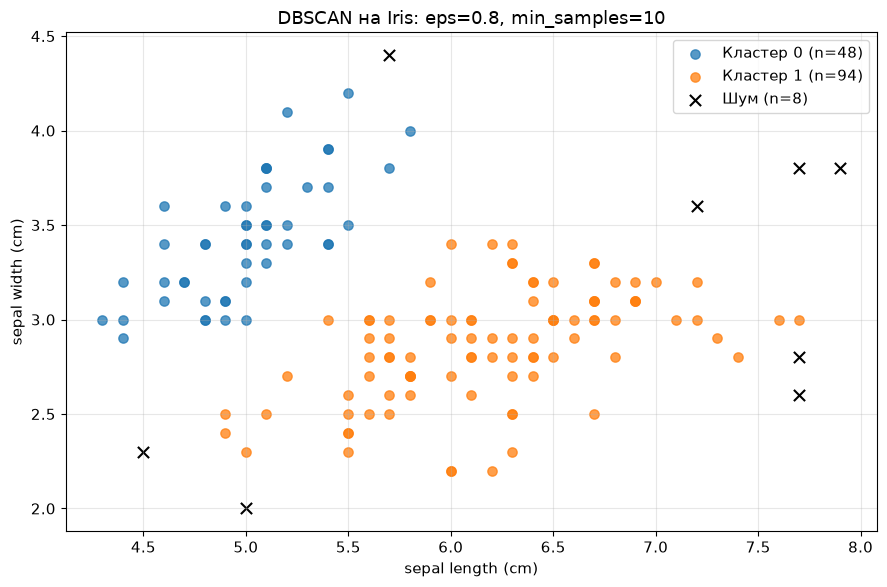

In [5]:
fig, ax = plt.subplots()
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

for index, cluster_id in enumerate(cluster_ids):
    mask = labels == cluster_id
    ax.scatter(
        iris_df.loc[mask, 'sepal length (cm)'],
        iris_df.loc[mask, 'sepal width (cm)'],
        color=colors[index % len(colors)], s=45, alpha=0.75,
        label=f'Кластер {cluster_id} (n={int(mask.sum())})'
    )

noise_mask = labels == -1
if noise_mask.any():
    ax.scatter(
        iris_df.loc[noise_mask, 'sepal length (cm)'],
        iris_df.loc[noise_mask, 'sepal width (cm)'],
        color='black', marker='x', s=65,
        label=f'Шум (n={int(noise_mask.sum())})'
    )

ax.set(xlabel='sepal length (cm)', ylabel='sepal width (cm)',
       title=f'DBSCAN на Iris: eps={best_eps}, min_samples={best_min_samples}')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


На осях показаны исходные измерения в сантиметрах. Метки кластеров
рассчитаны по всем четырём стандартизированным признакам, поэтому
возможное наложение групп в этой двумерной проекции не противоречит
полученному разбиению. Номер кластера – условная метка, а не название
вида ириса. DBSCAN определяет группы по плотности и не обязан находить
ровно столько кластеров, сколько известных биологических видов.


## Вывод

Изучил нормализацию данных, подбор параметров DBSCAN и визуализацию двух кластеров ирисов с восемью шумовыми объектами.


## Ответы на вопросы для защиты


### 1. В чём состоит задача кластеризации?

Кластеризация – объединение похожих объектов в группы без заранее заданных правильных меток. Сходство определяется выбранными признаками, расстоянием и алгоритмом. В работе группы формируются по четырём измерениям цветков Iris.


### 2. Для каких целей используется кластеризация?

Её применяют для исследования структуры данных, сегментации клиентов, группировки документов и изображений, выделения похожих наблюдений и поиска необычных объектов. Обнаруженные кластеры требуют содержательной интерпретации: группа не всегда совпадает с заранее известной категорией.


### 3. Объясните алгоритм Ллойда.

Алгоритм Ллойда используется для K-средних. Сначала задают K центров. Затем каждый объект относят к ближайшему центру, а каждый центр заменяют средним значением объектов его группы. Назначения и пересчёт повторяют до сходимости либо достижения ограничения итераций. Метод уменьшает сумму квадратов расстояний до центров и может сходиться к локальному минимуму, поэтому важны инициализация и повторные запуски.


### 4. Как выбрать число кластеров для K-средних?

Можно сравнить несколько K методом локтя: найти участок, после которого внутрикластерная сумма квадратов уменьшается значительно медленнее. Также используют silhouette, устойчивость разбиения и смысл задачи. Выраженный локоть бывает не всегда. В отличие от K-средних, DBSCAN не требует заранее указывать количество кластеров.


### 5. Объясните алгоритм DBSCAN.

DBSCAN ищет плотные области. Если в радиусе eps от точки находится не меньше min_samples объектов с учётом неё самой, точка считается ядерной. Связанные цепочками ядерных точек плотные области образуют кластеры. Неядерные точки в окрестностях ядерных могут стать граничными; остальные получают метку шума -1. Слишком маленький eps или большой min_samples увеличивают число шумовых точек, слишком большой eps может объединить группы. Признаки предварительно масштабируют, поскольку алгоритм использует расстояния.
